# Histórico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de datos

1. Completitud de variables


-------

El **Servicio Médico Forense del Distrito Federal (SEMEFO-DF)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. 
El **Histórico de Bitácoras Onomásticas (HBO)** son registros administrativos utilizados por el SEMEFO-DF entre **1968 y 1982** para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. 
Estas bitácoras contienen información individualizada sobre cada ingreso, como: nombre, fecha de ingreso, edad, diagnóstico de causa de muerte, expediente del SEMEFO, institución de procedencia y acta. 
Entre 2020 y 2023, la CNB accedió a estos documentos, resguardados por el INCIFO-CdMx, para digitalizar, transcribir e interpretar las anotaciones manuscritas. La base de datos se hizo pública por medio de la solicitud de acceso a la información 332163723000249 como un archivo en formato Excel.
Estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Esta serie de notebooks documenta el proceso de análisis al cual fue sometido el HBO. 
1. [/] Estadística descriptiva de variables: ver perfil de datos `HBO_profile_clean`
2. [/] Completitud de variables
3. [/] Comparación entre grupos según tipo de restos
    * [/] Categóricas: tablas de contingencia, chi^2
        * [/] Extra: aluvial des/conocido, tipo_restos, sexo 
    * [/] Texto: cadenas con mayor frecuencia y wordcloud
    * [/] Proceso administrativo: distribución en bitácoras y wordcloud
        * [/] Extra: mapa de procedencia_alcaldia
    * [/] Numéricas: medidas de tendencia central y dispersión, chi^2, Mann-Whitney U
        * [/] Extra: estimación de distribución de edad con KDE
4. [ ] Comparación con datos históricos
    * [/] Asociación ingresos y decesos DF: chi^2 y regresion lineal
    * [/] Ingresos anuales por sexo: gráfica
    * [ ] Distribución grupo etario
5. [ ] Red de coocurrencia de diagnósticos: ver `HBO_analisis_diag`
6. [ ] Asociación entre diagnóstico y tipo restos, sexo y edad grupo:  ver `HBO_analisis_diag`
    * [ ] chi-cuadrado con corrección (clasificación vs. tipo restos/sexo)
    * [ ] clustermap (clasificación vs. edad grupo)
7. [ ] Asociación entre procedencia y tipo de restos y sexo:
    * [ ] chi-cuadrado (clasificación vs. tipo restos/sexo)
    * [ ] clustermap (alcaldía vs. tipo restos)
8. [-] Análisis temporal

In [1]:
from joblib import load
import pandas as pd
import numpy as np
from numpy import nan
from helper_pandas import *
from scipy.stats import chi2_contingency, gaussian_kde, mannwhitneyu
import statsmodels.api as sm

from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.options.mode.chained_assignment = None 

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
display( df.shape )
df.tail()

(96825, 31)

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,Judicial,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,Hospital,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


### Código de color

1. <span style="background:#0504aa">---</span> Poblacion
2. <span style="background:#999999">---</span> S-D  <span style="background:#d9d9d9">---</span> S-D (DF)
3. <span style="background:#377eb8">---</span> Masculino  <span style="background:#80b1d3">---</span> Masculino (DF)
4. <span style="background:#984ea3">---</span> Femenino  <span style="background:#bebada">---</span> Femenino (DF)
5. <span style="background:#4daf4a">---</span> Conocido
6. <span style="background:#dbb40c">---</span> Desconocido
7. <span style="background:#04d8b2">---</span> Cadáver conocido
8. <span style="background:#fdff52">---</span> Cadáver desconocido
9. <span style="background:#c875c4">---</span> Recién nacido
10. <span style="background:#ff7f00">---</span> Feto
11. <span style="background:#f781bf">---</span> Miembros
12. <span style="background:#c85a53">---</span> Restos óseos 

In [2]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'S-D':'#999999', 'S-D (SEMEFO)':'#999999', 'S-D (DF)':'#d9d9d9', 
             'Masculino':'#377eb8', 'Masculino (SEMEFO)':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (SEMEFO)':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 'Feto':'#ff7f00', 'Miembros':'#f781bf', 'Restos óseos':'#c85a53', }
gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


## Completitud de variables

### Datos faltantes por columna transcrita

In [3]:
col_trans = [c for c in df.columns if 'transcrito' in c]
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan = (df[col_trans]!='S-D')
df_notnan.sum()

Numero_progresivo_transcrito    27152
Nombre_completo_transcrito      96819
Fecha_transcrito                96611
Edad_transcrito                 40183
Diagnostico_transcrito          40966
Procedencia_transcrito          71064
Numero_acta_transcrito          71102
Expediente_SEMEFO_transcrito    96277
Foja_transcrito                 88845
dtype: int64

**Datos faltantes por año**

No todos los años se capturaron todas las variables.

* Edad y Diagnóstico solo fueron capturadas de 1974-1979
* Numero progresivo solo fue capturada de 1974 a 1978 y fue de manera irregular
* Procedencia y acta fueron capturadas de manera irregular de 1968 a 1963
* Foja no fue capturada en 1980

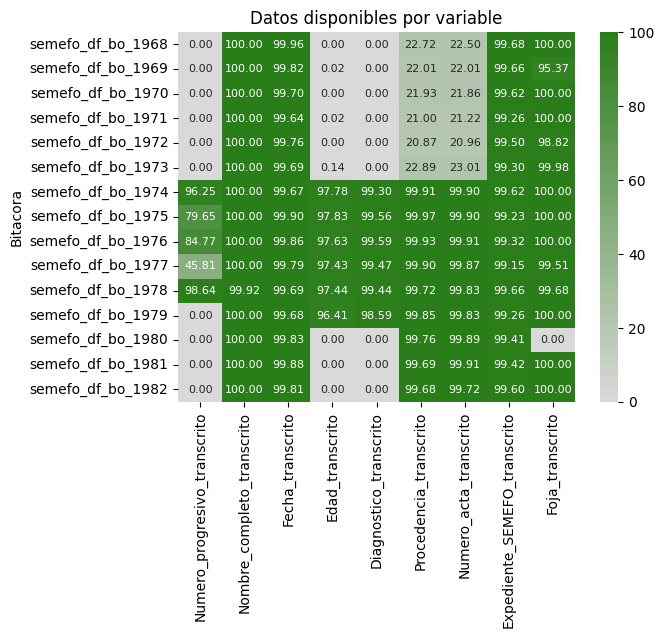

In [4]:
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan['Bitacora'] = df['Bitacora_ingresos']
df_notnan_anual = df_notnan.groupby('Bitacora').sum().divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable")
plt.show()

Ignorando las variables que no fueron capturadas en el año

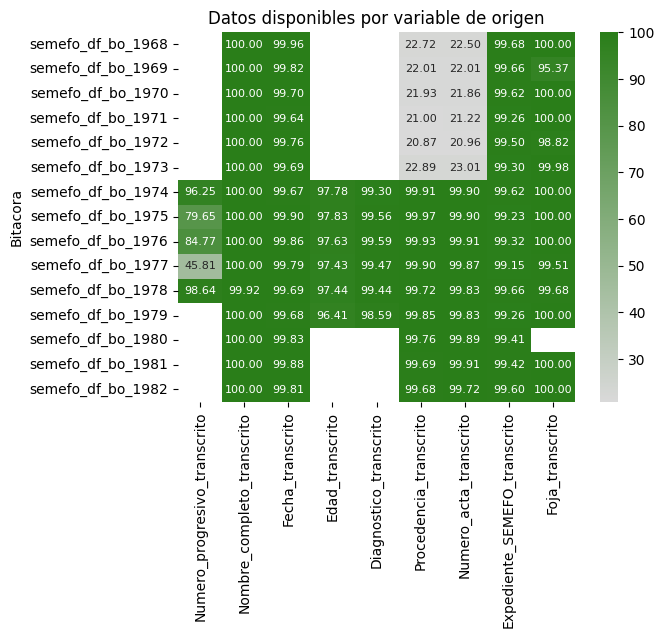

In [5]:
dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    df_notnan.loc[ df_notnan['Bitacora'].isin([f"semefo_df_bo_{a}" for a in años]), col] = nan
df_notnan

df_notnan_anual = df_notnan.groupby('Bitacora', dropna=False) \
                            .apply(lambda x: x.sum(skipna=False)) \
                            .divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable de origen")
#plt.savefig("imagenes/BO_VariableFaltante+Año.svg")
plt.show()

Correlación entre faltantes
* Existe una correlación alta  (0.996) entre la falta de procedencia y de acta.
* Existe una correlación debil entre la falta del nombre con la fecha (0.253) y el exp semefo (0.162)


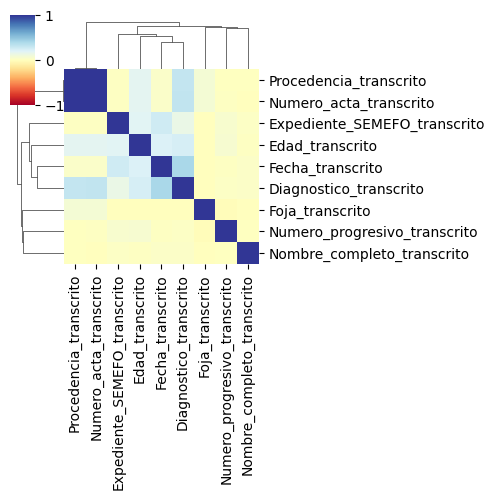

In [6]:
sns.clustermap(df_notnan.drop('Bitacora', axis=1).corr(), vmin=-1, vmax=1, cmap='RdYlBu', figsize=(5,5))
plt.show()

### Filas con más datos faltantes

* Casos donde hay número progresivo o foja pero ningun dato
* Casos donde solo hay nombre, muchas veces solo apellido
* Casos sin fecha pero con expediente

En general no parece haber un patrón, la cantidad de datos esta fuertemente asociada a que campos se capturaron ese año

In [7]:
df_notnan = (df[col_trans]!='S-D')
df_notnan['Bitacora'] = df['Bitacora_ingresos']

dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    años = [f"semefo_df_bo_{a}" for a in años]
    df_notnan.loc[ df_notnan['Bitacora'].isin(años), col] = nan

df_notnan_row = df_notnan.drop('Bitacora', axis=1).sum(axis=1).to_frame()
df_notnan_row.value_counts().sort_index()

0
1        6
2       58
3      459
4    25153
5     7900
6    22190
7      615
8    14044
9    26400
Name: count, dtype: int64

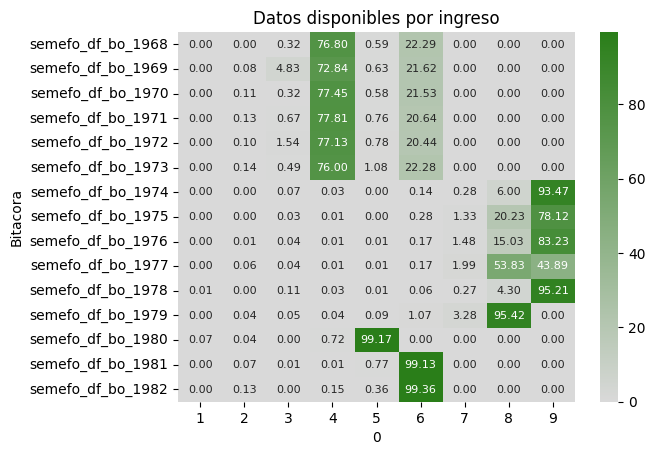

In [8]:
df_notnan_row['Bitacora'] = df['Bitacora_ingresos']
df_notnan_row_anual = df_notnan_row.pivot_table(columns=0, index='Bitacora', aggfunc='size')
df_notnan_row_anual = df_notnan_row_anual.divide(ingresos_anuales, axis=0)
sns.heatmap(df_notnan_row_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por ingreso")
plt.show()

### Faltantes por tipo de restos

* De 1968 a 1973 faltan procedencia/acta para cadáveres conocidos
* De 1974 a 1979 faltan edades para miembros
* No todos los años hay restos oseos


Cadáver conocido


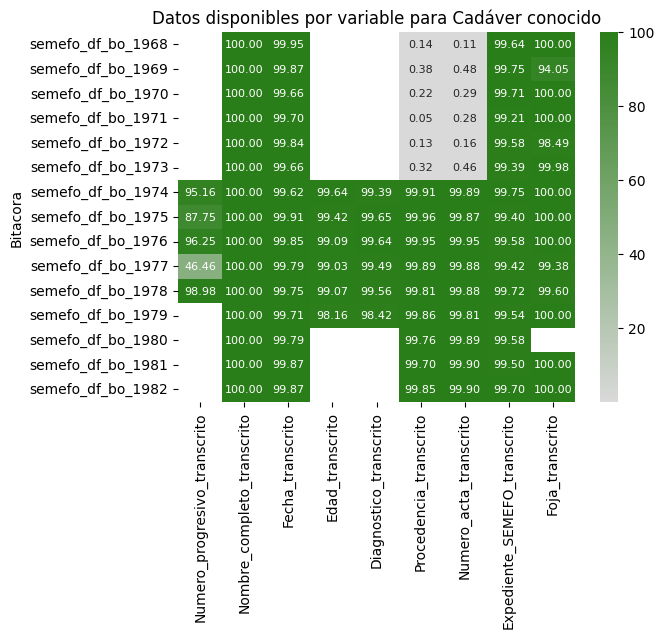

Cadáver desconocido


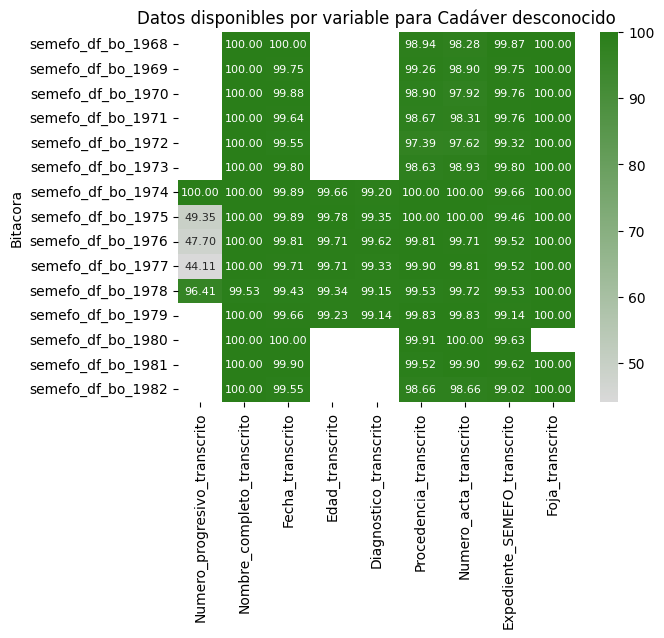

Miembros


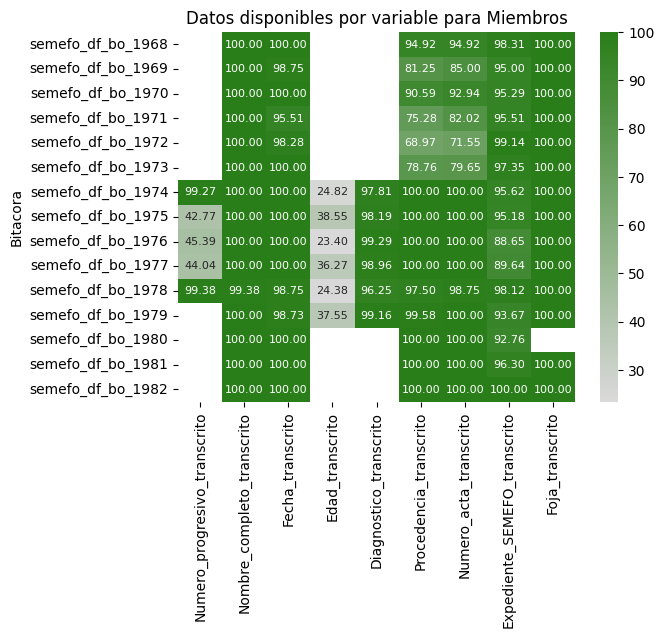

Feto


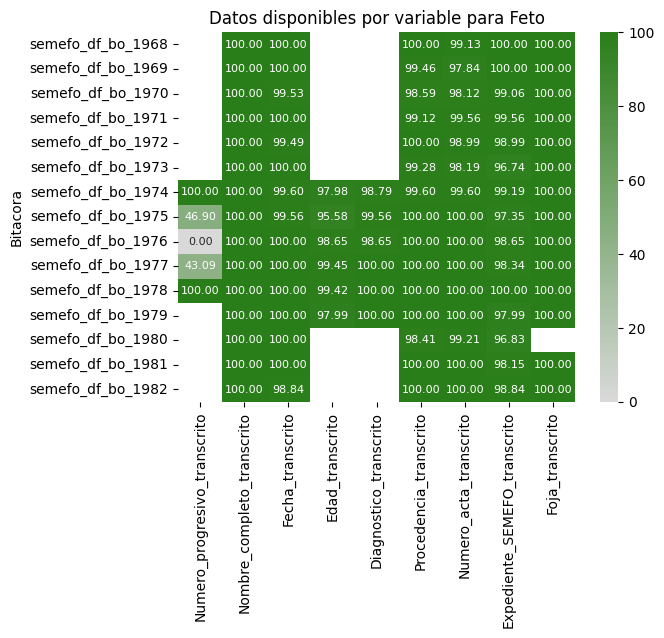

Restos óseos


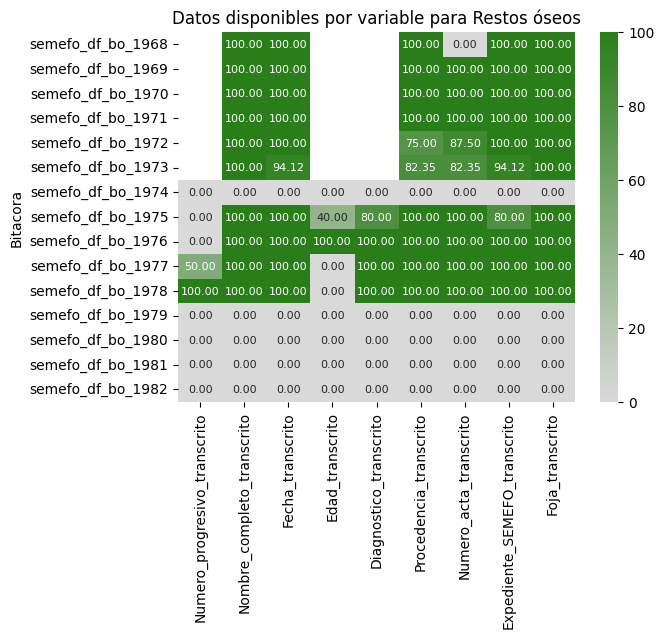

Recién nacido


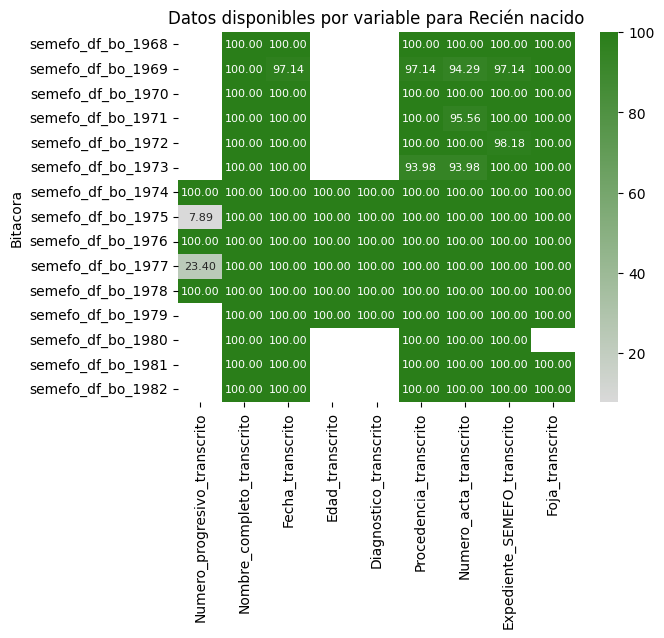

In [9]:
for tipo in df['Tipo_restos'].unique():
    print(tipo)
    ingresos_anuales_tipo = df.loc[df['Tipo_restos']==tipo,'Bitacora_ingresos'].value_counts().sort_index()
    ingresos_anuales_tipo = ingresos_anuales_tipo.replace({0:1.0})
    data = df_notnan[df['Tipo_restos']==tipo]
    data_anual = data.groupby('Bitacora', dropna=False) \
                     .apply(lambda x: x.sum(skipna=False)) \
                     .div( ingresos_anuales_tipo, axis=0 )
    for col in data_anual.columns:
        data_anual[col] = pd.to_numeric(data_anual[col]*100)
    sns.heatmap(data_anual, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
    plt.title(f"Datos disponibles por variable para {tipo}")
    plt.show()

## Comparación entre grupos según tipo de restos

### Categóricas:
#### Tipo_restos (chi^2)

In [10]:
categorical_to_freq_and_percentage(df['Tipo_restos']).to_frame().transpose()

Tipo_restos,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,76756 (79.273%),14479 (14.954%),633 (0.654%),2844 (2.937%),2065 (2.133%),48 (0.05%)


#### Conocido_desconocido (chi^2)

In [11]:
categorical_summary(df['Conocido_desconocido'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Conocido_desconocido,,,,,,,
Conocido,76756 (79.273%),0 (0.0%),31 (0.032%),31 (0.032%),1795 (1.854%),0 (0.0%),78613 (81.191%)
Desconocido,0 (0.0%),14479 (14.954%),602 (0.622%),2813 (2.905%),270 (0.279%),48 (0.05%),18212 (18.809%)
S-D,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


**Prueba de independencia $\chi^2$**

Supuestos:
* Variables Categóricas
* Observaciones Independientes: unir cadáveres
* Frecuencias Esperadas Suficientes: quitar `Restos óseos` y `S-D`
* Muestra Aleatoria Simple

Resultado:
**Muestra no independientes**: Chi-square: 14946.61
**Estadísticamente significativa**: P-value: 0.0

In [12]:
data = df.pivot_table(index='Tipo_restos',columns='Conocido_desconocido', aggfunc='size')
data.loc['Cadáver'] = data.loc['Cadáver conocido'] + data.loc['Cadáver desconocido']
data = data.drop(index=['Cadáver conocido','Cadáver desconocido', 'Restos óseos'], columns='S-D')
display(data)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid = resid.where(np.abs(resid) > thr_resid)
#display( resid )

Conocido_desconocido,Conocido,Desconocido
Tipo_restos,,
Recién nacido,31,602
Feto,31,2813
Miembros,1795,270
Cadáver,76756,14479


Chi-square statistic: 14946.610717206737
Degrees of freedom: 3
P-value: 0.0


#### Sexo (chi^2)

In [13]:
categorical_summary(df['Sexo'], df['Tipo_restos'], percen_round=3, as_str=True)

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Sexo,,,,,,,
Femenino,17923 (18.511%),1580 (1.632%),251 (0.259%),462 (0.477%),384 (0.397%),1 (0.001%),20601 (21.277%)
Masculino,58337 (60.25%),12845 (13.266%),379 (0.391%),662 (0.684%),1511 (1.561%),7 (0.007%),73741 (76.159%)
S-D,496 (0.512%),54 (0.056%),3 (0.003%),1720 (1.776%),170 (0.176%),40 (0.041%),2483 (2.564%)


**Prueba de independencia $\chi^2$**

Supuestos:
* Variables Categóricas
* Observaciones Independientes
* Frecuencias Esperadas Suficientes: quitar `Restos óseos`
* Muestra Aleatoria Simple

Resultado:
**Muestra no independientes**: Chi-square: 66051.22
**Estadísticamente significativa**: P-value: 0.0

In [14]:
data = df.pivot_table(index='Tipo_restos',columns='Sexo', aggfunc='size')
data = data.drop(index='Restos óseos')
display(data)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid = resid.where(np.abs(resid) > thr_resid)
#display( resid )

Sexo,Femenino,Masculino,S-D
Tipo_restos,,,
Cadáver conocido,17923,58337,496
Cadáver desconocido,1580,12845,54
Recién nacido,251,379,3
Feto,462,662,1720
Miembros,384,1511,170


Chi-square statistic: 41849.52791700521
Degrees of freedom: 8
P-value: 0.0


#### Des/conocido, tipo restos, sexo (aluvial)

Relación entre variables categóricas

In [15]:
import plotly.graph_objects as go

cols = ['Conocido_desconocido', 'Tipo_restos', 'Sexo']

data = df[cols].value_counts().reset_index()
data.columns = cols + ['freq']
data.head()

# Step 1: Build all unique labels
labels = pd.unique(data[cols].values.ravel()).tolist()
label_index = {l: i for i, l in enumerate(labels)}
label_colors = [dic_color.get(label, 'lightgray') for label in labels]

# Step 2: Create source-target pairs
links = list()
for s,t in zip(cols, cols[1:]):
    link = data.groupby([s,t])['freq'].sum().reset_index()
    link['source'] = link[s].map(label_index)
    link['target'] = link[t].map(label_index)
    links.append( link[['source','target','freq']] )
    
links = pd.concat(links)
links.head()

# Step 3: Build the Sankey diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=30,
        thickness=150,
        line=dict(color="black", width=0.5),
        label=labels,
        color=label_colors
    ),
    link=dict(
        source=links['source'],
        target=links['target'],
        value=links['freq']
    )
)])

fig.update_layout(title_text="Tipo de restos", 
                  width=900,height=600,
                  font_size=16)
fig.show()

#import plotly.io as pio
#pio.write_image(fig, "imagenes/BO_Sankey_Conocido+Tipo+Sexo.svg", format='svg')

#### Diagnostico_clasificacion

In [16]:
categorical_to_freq_and_percentage(df['Diagnostico_clasificacion'], sort_index=False, top_n=12) \
    .to_frame().transpose()

Diagnostico_clasificacion,Traumatismos,Causas externas,Herida arma de fuego,Respiratorio,Digestivo,"Sintomas, signos y hallazgos anormales",Afecciones periodo perinatal,Sin datos,Circulatorio,Herida punzo cortante,Amputación,Infecciosas y parasitarias
0,20130 (20.79%),4398 (4.542%),3364 (3.474%),2385 (2.463%),1617 (1.67%),1438 (1.485%),1172 (1.21%),1086 (1.122%),956 (0.987%),836 (0.863%),694 (0.717%),390 (0.403%)


In [17]:
string_summary(df['Diagnostico_clasificacion'], df['Tipo_restos'], 
               top_n=10, other_str='Otro*',
               percen_round=3, pretty_display=True)
None

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Traumatismos 17199 (17.763%),Traumatismos 2832 (2.925%),Afecciones periodo perinatal 81 (0.084%),Afecciones periodo perinatal 1035 (1.069%),Amputación 677 (0.699%),Sin datos 4 (0.004%)
1,Causas externas 3860 (3.987%),Respiratorio 827 (0.854%),Causas externas 33 (0.034%),Sin datos 37 (0.038%),Amputación + Piel y del tejido subcutáneo 57 (0.059%),Traumatismos 3 (0.003%)
2,Herida arma de fuego 3097 (3.199%),Digestivo 697 (0.72%),Respiratorio 32 (0.033%),Causas externas 28 (0.029%),Piel y del tejido subcutáneo 53 (0.055%),Herida arma de fuego 1 (0.001%)
3,Respiratorio 1513 (1.563%),Causas externas 453 (0.468%),Traumatismos 27 (0.028%),Traumatismos 26 (0.027%),Traumatismos 43 (0.044%),Afecciones periodo perinatal 0 (0.0%)
4,"Sintomas, signos y hallazgos anormales 1231 (1.271%)",Herida arma de fuego 259 (0.267%),Digestivo 10 (0.01%),Respiratorio 12 (0.012%),Amputación + Causas externas 27 (0.028%),Amputación 0 (0.0%)
5,Sin datos 1002 (1.035%),"Sintomas, signos y hallazgos anormales 203 (0.21%)",Causas externas + Traumatismos 5 (0.005%),Digestivo 3 (0.003%),Causas externas 24 (0.025%),Afecciones periodo perinatal + Causas externas 0 (0.0%)
6,Digestivo 907 (0.937%),Circulatorio 149 (0.154%),Sin datos 3 (0.003%),Causas externas + Traumatismos 3 (0.003%),Amputación + Infecciosas y parasitarias 15 (0.015%),Afecciones periodo perinatal + Digestivo 0 (0.0%)
7,Circulatorio 802 (0.828%),Infecciosas y parasitarias 140 (0.145%),Herida punzo cortante 2 (0.002%),Afecciones periodo perinatal + Causas externas 3 (0.003%),Sin datos 11 (0.011%),Afecciones periodo perinatal + Traumatismos 0 (0.0%)
8,Herida punzo cortante 735 (0.759%),Herida punzo cortante 99 (0.102%),"Sintomas, signos y hallazgos anormales + Traumatismos 2 (0.002%)","Embarazo, parto y puerperio 2 (0.002%)",Amputación + Herida arma de fuego 7 (0.007%),"Amputación + Endocrinas, nutricionales y metabólicas 0 (0.0%)"
9,Infecciosas y parasitarias 246 (0.254%),Digestivo + Infecciosas y parasitarias 43 (0.044%),"Sintomas, signos y hallazgos anormales 2 (0.002%)","Sintomas, signos y hallazgos anormales 2 (0.002%)",Piel y del tejido subcutáneo + Traumatismos 6 (0.006%),Amputación + Herida arma de fuego 0 (0.0%)


#### Procedencia_clasificacion

In [18]:
categorical_to_freq_and_percentage(df['Procedencia_clasificacion'], sort_index=False, top_n=12) \
    .to_frame().transpose()

Procedencia_clasificacion,Judicial,Hospital,Hospital + Judicial
0,45501 (46.993%),25139 (25.963%),85 (0.088%)


In [19]:
categorical_summary(df['Procedencia_clasificacion'], df['Tipo_restos'], percen_round=3, as_str=True)

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Procedencia_clasificacion,,,,,,,
Hospital,19533 (20.174%),3969 (4.099%),87 (0.09%),496 (0.512%),1051 (1.085%),3 (0.003%),25139 (25.963%)
Hospital + Judicial,76 (0.078%),7 (0.007%),0 (0.0%),0 (0.0%),2 (0.002%),0 (0.0%),85 (0.088%)
Judicial,31540 (32.574%),10261 (10.597%),517 (0.534%),2250 (2.324%),894 (0.923%),39 (0.04%),45501 (46.993%)


### Texto:

#### Nombre_completo_transcrito (wordcloud)

In [20]:
string_summary(df['Nombre_completo_transcrito'], df['Tipo_restos'], 
               top_n=5,  other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,hernandez hernandez jesus 7 (0.007%),desconocido 12820 (13.24%),r. nacido 224 (0.231%),feto 2609 (2.695%),nombre confidencial 1880 (1.942%),osamenta 30 (0.031%)
1,hernandez hernandez antonio 6 (0.006%),desconocida 1291 (1.333%),recien nacido 105 (0.108%),nombre confidencial 202 (0.209%),restos humanos 26 (0.027%),restos oseos 8 (0.008%)
2,lopez lopez mario 6 (0.006%),S-D 5 (0.005%),r. nacida 96 (0.099%),fetos 6 (0.006%),placenta 11 (0.011%),desconocido 3 (0.003%)
3,garcia garcia juan 6 (0.006%),desconocido o guadalupe 4 (0.004%),nombre confidencial 72 (0.074%),desconocido (feto) 4 (0.004%),m.i. de: 8 (0.008%),huesos humanos 2 (0.002%)
4,lopez hernandez jose 5 (0.005%),"desconocido o pedro ""n"" 4 (0.004%)",recien nacida 61 (0.063%),desconocida (feto) 2 (0.002%),miembro inferior 7 (0.007%),craneo 2 (0.002%)
5,Otro* 76726 (79.242%),Otro* 355 (0.367%),Otro* 75 (0.077%),Otro* 21 (0.022%),Otro* 133 (0.137%),Otro* 3 (0.003%)


''

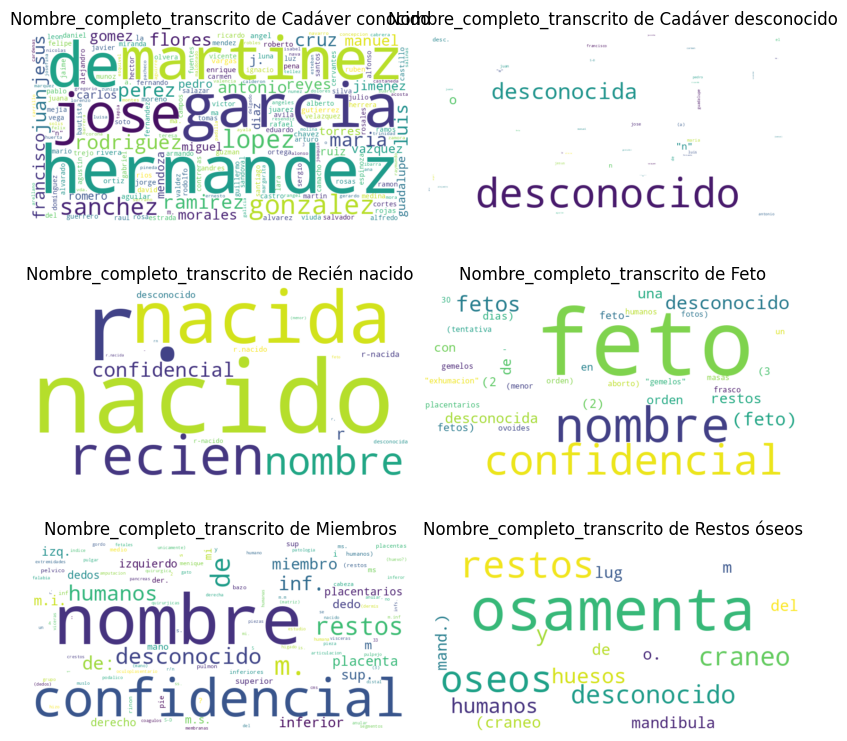

In [21]:
data = df.groupby('Tipo_restos').agg({'Nombre_completo_transcrito':join_strings_with_nans})
data = data.to_dict()['Nombre_completo_transcrito']
data

fig, axes = plt.subplots(nrows=3, ncols=2,figsize=(8,8))
axes = axes.flatten()

for ax,text in zip(axes,data.items()):
    # get word frequency
    freq = {}
    for word in text[1].split():
        freq[word] = freq.get(word, 0) + 1
    # create wordcloudx
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          background_color='white') \
                          .generate_from_frequencies(freq)
    # Display the word cloud
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f"Nombre_completo_transcrito de {text[0]}")

plt.tight_layout()
#plt.savefig("imagenes/WordcloudNombre+TipoRestos.svg")
plt.show()

#### Procedencia_extendido (mapa)

In [22]:
string_summary(df['Procedencia_extendido'], df['Tipo_restos'], 
               top_n=5,  other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Cruz Roja (Col Polanco) 3983 (4.114%),Coord Territorial 1 Venustiano Carranza (Col Merced) 1179 (1.218%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 88 (0.091%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 310 (0.32%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 425 (0.439%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 8 (0.008%)
1,Hospital Balbuena (Col Jardin Balbuena) 3954 (4.084%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 1170 (1.208%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 41 (0.042%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 173 (0.179%),Hospital Balbuena (Col Jardin Balbuena) 275 (0.284%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 7 (0.007%)
2,Coord Territorial 2 Coyoacan (Col Romero de Terreros) 3166 (3.27%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 1123 (1.16%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 41 (0.042%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 137 (0.141%),Hospital Xoco (Col General Anaya) 199 (0.206%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 5 (0.005%)
3,Hospital la Villa (Col Granjas Modernas) 2822 (2.915%),Hospital Balbuena (Col Jardin Balbuena) 1116 (1.153%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 36 (0.037%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 134 (0.138%),Cruz Roja (Col Polanco) 176 (0.182%),Coord Territorial 8 Cuauhtemoc (Col Obrera) 4 (0.004%)
4,Hospital Xoco (Col General Anaya) 2768 (2.859%),Cruz Roja (Col Polanco) 686 (0.708%),Coord Territorial 6 Cuauhtemoc (Col Centro) 32 (0.033%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 129 (0.133%),Hospital Ruben Leñero (Col Santo Tomas) 136 (0.14%),Coord Territorial 1 Tlalpan (Col Ampliacion Miguel Hidalgo) 3 (0.003%)
5,Otro* 60063 (62.033%),Otro* 9205 (9.507%),Otro* 395 (0.408%),Otro* 1961 (2.025%),Otro* 854 (0.882%),Otro* 21 (0.022%)


''

In [23]:
categorical_summary(df['Procedencia_alcaldia'], df['Tipo_restos'], percen_round=3, as_str=True, sort_index=False, top_n=15)

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Procedencia_alcaldia,,,,,,,
Miguel Hidalgo,8919 (9.211%),1849 (1.91%),67 (0.069%),295 (0.305%),343 (0.354%),3 (0.003%),11476 (11.852%)
Cuauhtemoc,7472 (7.717%),2952 (3.049%),100 (0.103%),442 (0.456%),167 (0.172%),9 (0.009%),11142 (11.507%)
Gustavo A Madero,6600 (6.816%),1874 (1.935%),125 (0.129%),464 (0.479%),222 (0.229%),7 (0.007%),9292 (9.597%)
Venustiano Carranza,5797 (5.987%),2860 (2.954%),43 (0.044%),248 (0.256%),304 (0.314%),0 (0.0%),9252 (9.555%)
Benito Juarez,5921 (6.115%),1174 (1.212%),59 (0.061%),356 (0.368%),312 (0.322%),1 (0.001%),7823 (8.08%)
Coyoacan,5212 (5.383%),408 (0.421%),46 (0.048%),148 (0.153%),474 (0.49%),5 (0.005%),6293 (6.499%)
Iztapalapa,3292 (3.4%),1058 (1.093%),64 (0.066%),244 (0.252%),36 (0.037%),4 (0.004%),4698 (4.852%)
Alvaro Obregon,2000 (2.066%),420 (0.434%),46 (0.048%),167 (0.172%),16 (0.017%),0 (0.0%),2649 (2.736%)
Azcapotzalco,1583 (1.635%),454 (0.469%),23 (0.024%),154 (0.159%),31 (0.032%),8 (0.008%),2253 (2.327%)


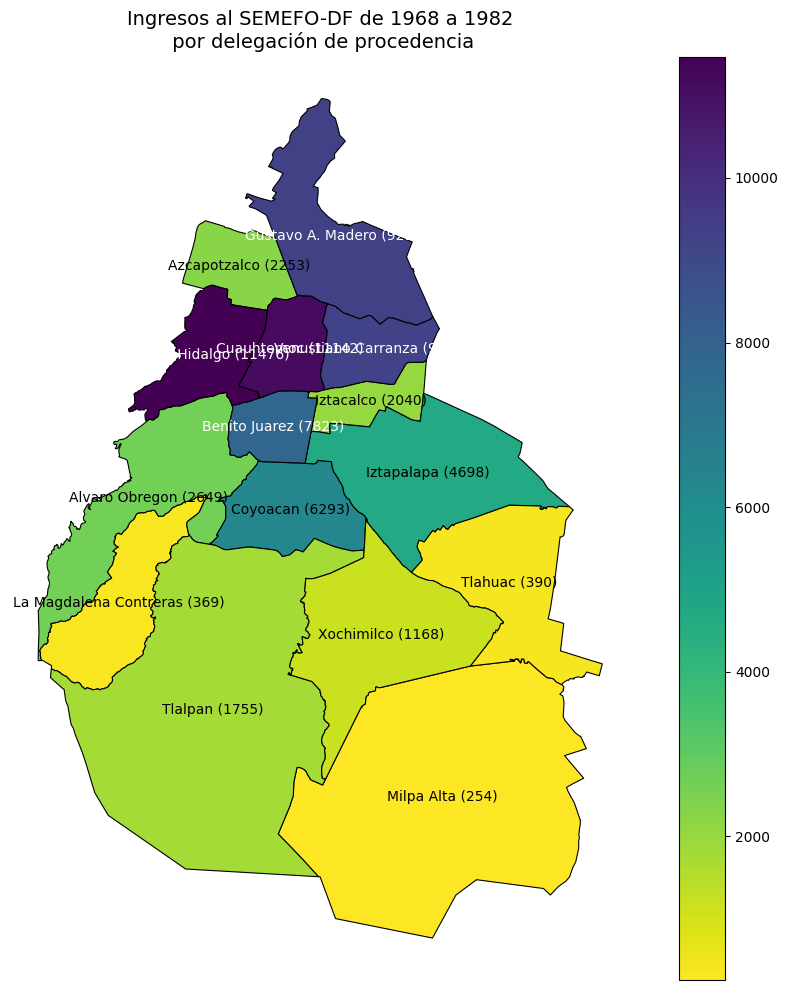

In [24]:
import geopandas as gpd

# capa de entidad y delegacion
mg_ent = gpd.read_file("catalogos/09_ciudaddemexico.zip!conjunto_de_datos", layer="09ent")
mg_mun = gpd.read_file("catalogos/09_ciudaddemexico.zip!conjunto_de_datos", layer="09mun")
mg_mun['NOMGEO'] = mg_mun['NOMGEO'].apply(unidecode)
mg_mun = mg_mun[['NOMGEO','geometry']]
mg_mun


# get freq
data = df['Procedencia_alcaldia'].value_counts(dropna=False).reset_index()
dic_rep = {'Gustavo A Madero':'Gustavo A. Madero', 'Magdalena Contreras':'La Magdalena Contreras', 'Cuajimalpa':'Cuajimalpa de Morelos'}
data['Procedencia_alcaldia'] = data['Procedencia_alcaldia'].replace(dic_rep)
data.columns = ['NOMGEO','freq']
# manage nan
nan_str, nan_otro = 'S-D', 'Otro'
data['NOMGEO'] = data['NOMGEO'].astype(str).replace({'nan':nan_str,nan:nan_str})
# filter 
data['NOMGEO'] = data['NOMGEO'].map({s:s for s in mg_mun['NOMGEO'].to_list() + [nan_str]}).fillna(nan_otro)
data = data.groupby('NOMGEO').sum().sort_index().reset_index()
# join with geometry
data = mg_mun.merge(data, on='NOMGEO')
#display( data )

# plot figure
fig, ax = plt.subplots(figsize=(10, 10))
data.plot(column='freq', cmap='viridis_r', linewidth=0.8, edgecolor='black', legend=True, ax=ax)

# Crear etiqueta con nombre del municipio y frecuencia entre paréntesis
data['etiqueta'] = data['NOMGEO'] + ' (' + data['freq'].astype(str) + ')'

# Añadir nombres de municipios con frecuencia
for idx, row in data.iterrows():
    if row.geometry.centroid.is_empty: continue
    x, y = row.geometry.centroid.x, row.geometry.centroid.y
    color = 'white' if row['freq'] > 7500 else 'black'
    ax.text(x, y, row['etiqueta'], fontsize=10, 
            ha='center', va='center', 
            color=color)

ax.set_title('Ingresos al SEMEFO-DF de 1968 a 1982\n por delegación de procedencia', fontsize=14)
ax.axis('off')
plt.tight_layout()
#plt.savefig("imagenes/BO_Mapa_Ingresos.svg")
plt.show()

#### Diagnostico_extendido


In [25]:
string_summary(df['Diagnostico_extendido'], df['Tipo_restos'], 
               top_n=5,  other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,traumatismo multiple 6095 (6.295%),traumatismo multiple 1427 (1.474%),asfixia neo natorum 75 (0.077%),expulsion prematura del seno materno 542 (0.56%),amputacion quirurgica por traumatismo 602 (0.622%),indeterminado 3 (0.003%)
1,traumatismo craneo encefalico 5200 (5.371%),traumatismo craneo encefalico 775 (0.8%),bronconeumonia 29 (0.03%),asfixia neo natorum 461 (0.476%),gangrena 45 (0.046%),traumatismo craneo encefalico 2 (0.002%)
2,bronconeumonia 1185 (1.224%),bronconeumonia 682 (0.704%),asfixia por estrangulacion 16 (0.017%),indeterminado 36 (0.037%),traumatismo miembro 33 (0.034%),no copias 1 (0.001%)
3,congestion visceral generalizada 1142 (1.179%),bronconeumonia + cirrosis hepatica 425 (0.439%),traumatismo craneo encefalico 13 (0.013%),falta cuidado post natales 18 (0.019%),amputacion quirurgica por traumatismo + gangrena 30 (0.031%),traumatismo cervico 1 (0.001%)
4,traumatismo craneo torax 1030 (1.064%),congestion visceral generalizada 193 (0.199%),bronconeumonia + enteritis 7 (0.007%),traumatismo craneo encefalico 14 (0.014%),amputacion traumatica 29 (0.03%),herida arma fuego craneo 1 (0.001%)
5,Otro* 62104 (64.14%),Otro* 10977 (11.337%),Otro* 493 (0.509%),Otro* 1773 (1.831%),Otro* 1326 (1.369%),Otro* 40 (0.041%)


''

### Proceso administrativo

'Numero_progresivo_transcrito', 
'Expediente_SEMEFO_transcrito',
'Foja_transcrito', 
'Observaciones'

#### Numero_progresivo
* El orden es por letra, luego fecha.
* Generalmente desconocidos, fetos, etc al final

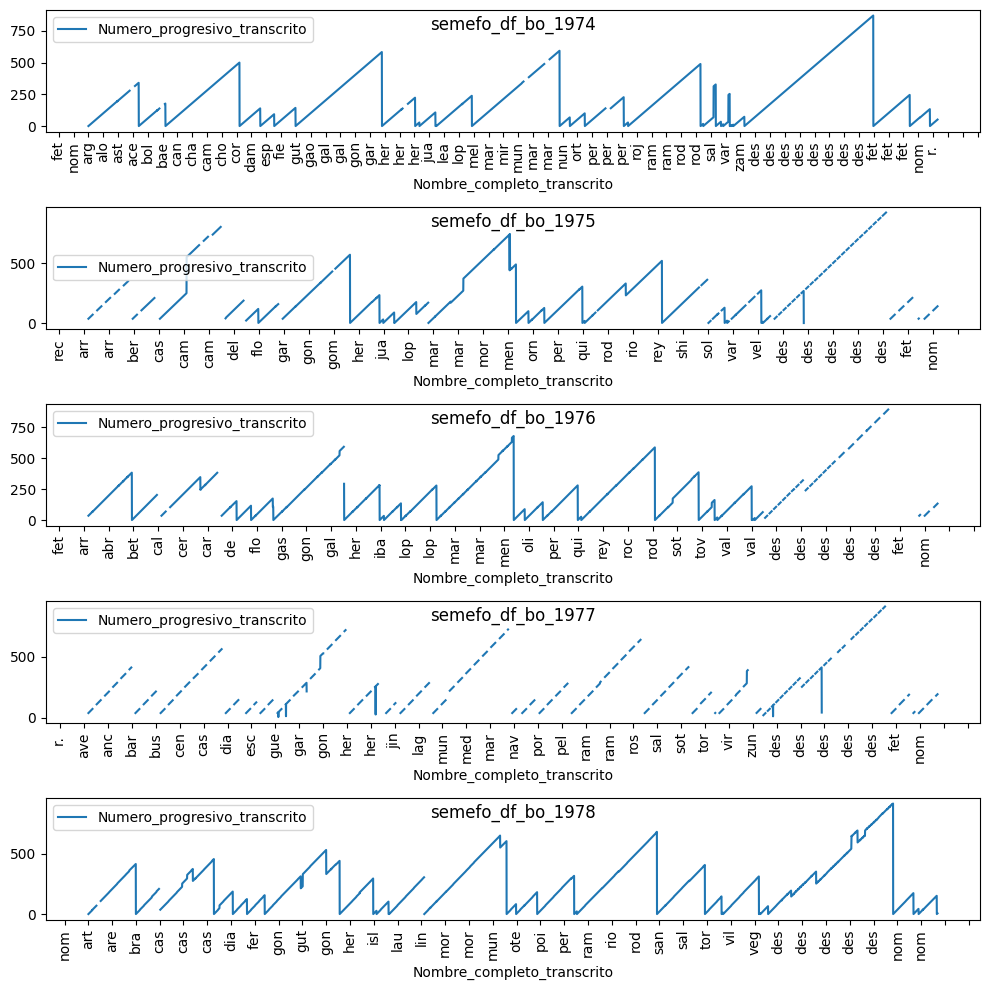

In [26]:
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 10))


i = 0
for bit in [f'semefo_df_bo_{i}' for i in range(1974, 1979)]:
    data = df.loc[(df['Bitacora_ingresos']==bit), ['Nombre_completo_transcrito','Numero_progresivo_transcrito']]
    if data.shape[0]>0:
        data['Nombre_completo_transcrito'] = data['Nombre_completo_transcrito'].apply(lambda s: s[0:3] if type(s)==str else nan)
        data['Numero_progresivo_transcrito'] = pd.to_numeric( data['Numero_progresivo_transcrito'].replace('S-D',nan) )
        data = data.set_index('Nombre_completo_transcrito')
        axes[i].set_title(bit, y=1.0, pad=-14)
        axes[i].locator_params(axis='x', nbins=70)
        #axes[i].get_legend().remove()
        data.plot(ax=axes[i], rot=90)
        i += 1
plt.tight_layout()
plt.show()

#### Expediente_SEMEFO_transcrito

* El orden es por letra, luego fecha.
* De 1968 a 1973 en orden ortográfico + fecha
* De 1974 a 1982 desconocidos, fetos, etc al final

Exp no númericos: [nan '1-/69' '759-Bis' '26/70' '27/70' '25/71' '1971-10-01 00:00:00'
 '2196 R' '85-72' '1972-12-01 00:00:00' '29-72' '30-72' '28-72' '61-71'
 '78-72' '(90235) 1' '82-81' '3549-Bis' '57/73' 'R.L' 'RL' '39/75' '60/75'
 '6329/73' 'S/n' '34/75' '40/75' '4415 BIS' '251-76' '6725 Bis' '1080 Bis'
 '187-76' '3628 Bis' '250-76' '252-76' '6576 Bis' '2881 Bis' '6254 Bis'
 '136-Bis' '6900-75' '6903-75' '8/77' '1950 Bis' '323 Bis' '3014 bis'
 '1977-01-01 00:00:00' '2459-83' 'S-d' '359/78' '361/78' '371/78' '372/78'
 '362/78' '363/78' '379/78' '3092 Bis' '1.1/78' '1365 Bis' '5997 Bis'
 '364/78' '377/78' '366/78' '905 Bis' '376/78' '6249 bis' '360/78'
 '370/78' '374/78' '369/78' '375/78' '373/78' '378/78' '365/78' '801/79'
 '828/79' '831/79' '842/79' '824/79' '830/79' '-1-' '818/79' '827/79'
 '832/79' '834/79' '835-79' '7161-77' '375A' '816-79' '840-79' '817-79'
 '821-79' '822-79' '839-79' '829-79' '382-79' '826-79' '836-79' '838-79'
 '2721 Bis' '823-79' '837-79' '6968-77' '833-79' 

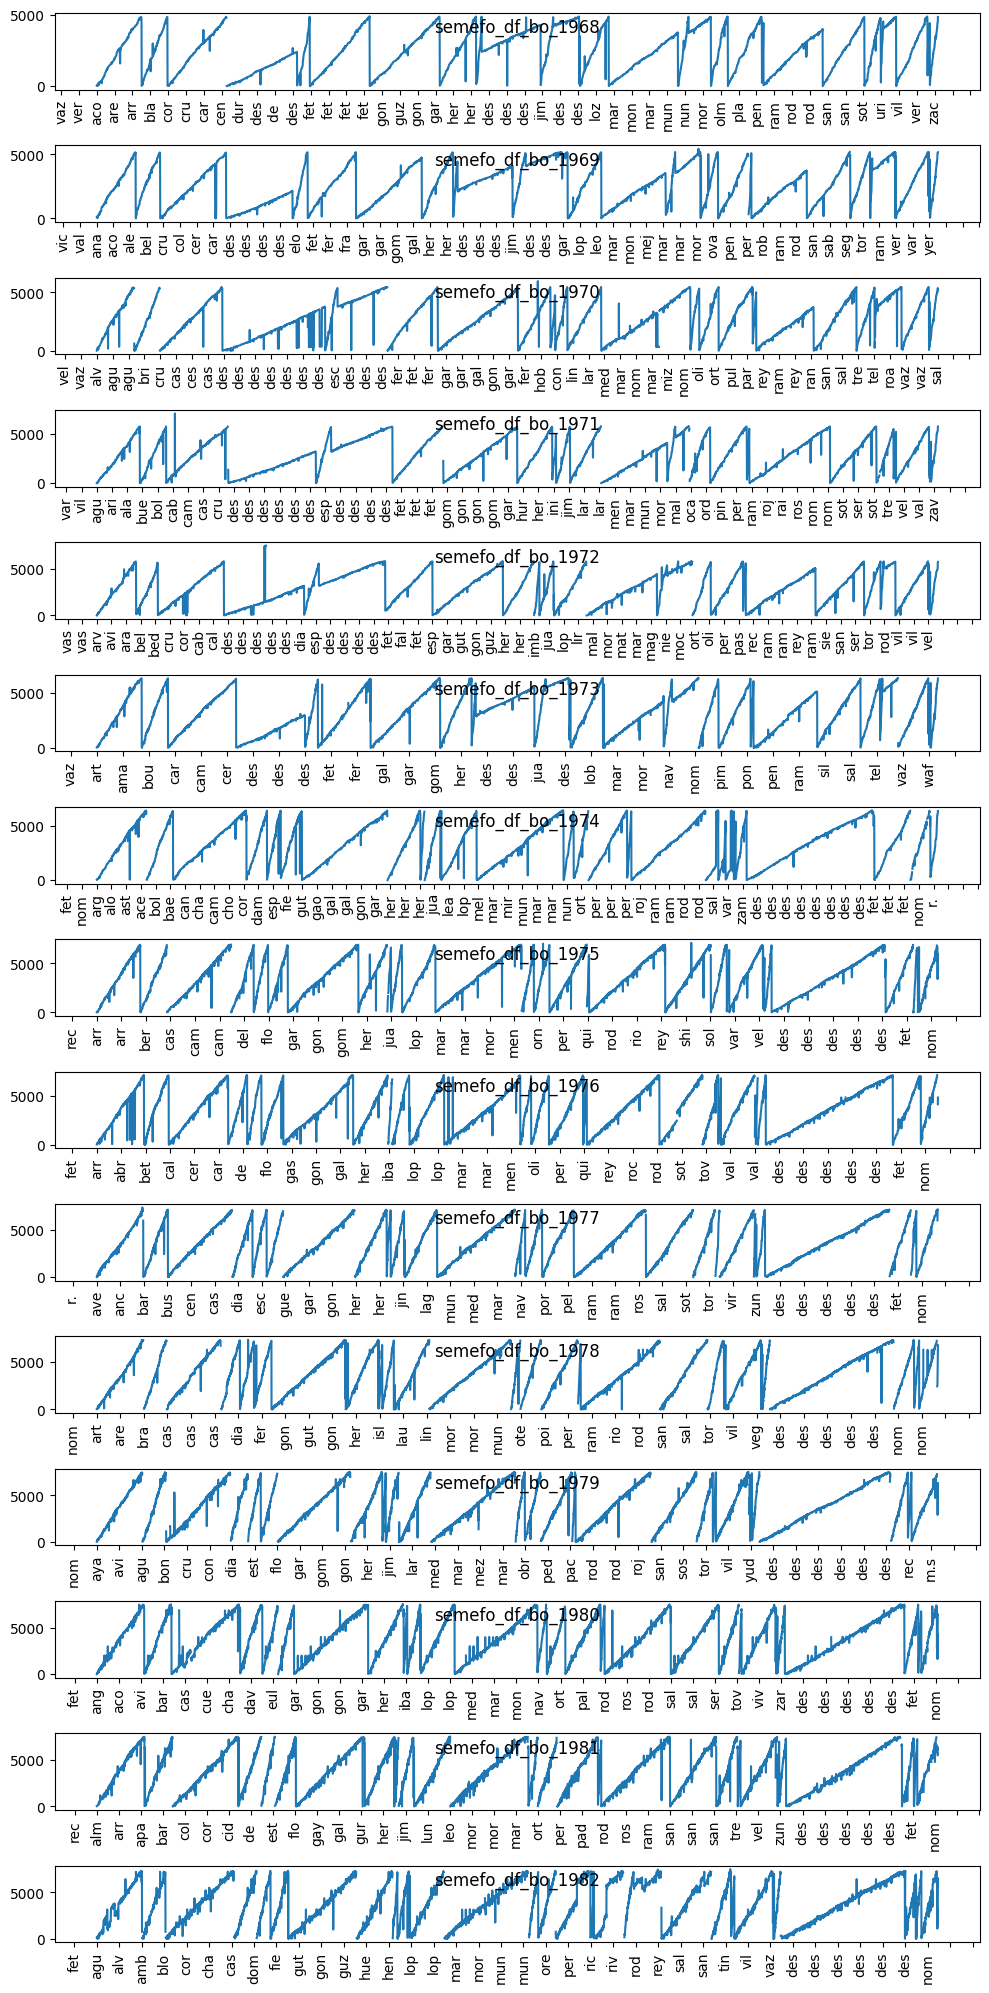

In [28]:
exp_sem = df[['Bitacora_ingresos','Nombre_completo_transcrito','Expediente_SEMEFO_transcrito']]
exp_sem.columns = ['Bitacora','Nombre','Exp']
exp_sem = to_dtype_with_errors(exp_sem, 'Exp', dtype='numeric', suffix='clean')
exp_sem

print('Exp no númericos:', exp_sem['Exp_error'].unique())

fig, axes = plt.subplots(nrows=15, ncols=1, figsize=(10, 20))

i = 0
for bit in [f'semefo_df_bo_{i}' for i in range(1968, 1983)]:
    data = exp_sem[(exp_sem['Bitacora']==bit)]
    if data.shape[0]>0:
        data['Nombre'] = data['Nombre'].apply(lambda s: s[0:3] if type(s)==str else nan)
        data.loc[data['Exp_clean']>=7500,'Exp_clean'] = nan
        data = data.set_index('Nombre')
        axes[i].set_title(bit, y=1.0, pad=-14)
        axes[i].locator_params(axis='x', nbins=70)
        data['Exp_clean'].plot(ax=axes[i], rot=90)
        axes[i].set_xlabel('')
        i += 1
plt.tight_layout()
plt.show()

#### Foja_transcrito

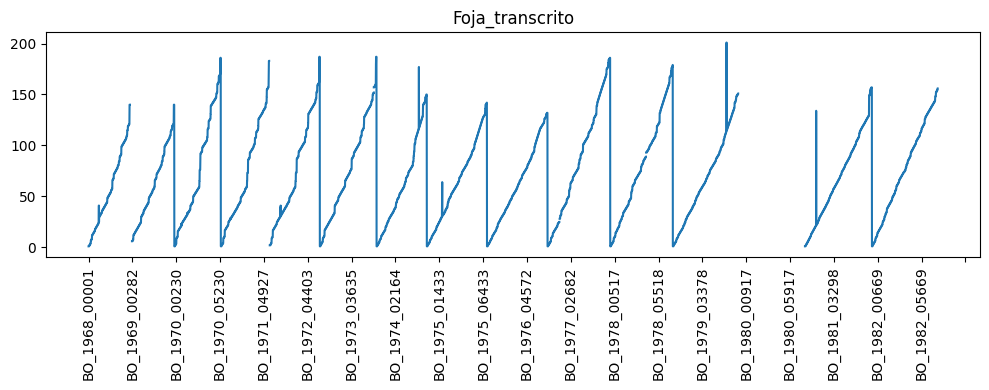

In [29]:
import re
get_digits = lambda s: int(re.findall(r'\d+',s)[0]) if type(s)==str else s
data = df['Foja_transcrito'].replace('S-D',nan).apply(get_digits)
data

fig, axes = plt.subplots(figsize=(10, 4))
axes.set_title('Foja_transcrito')
axes.locator_params(axis='x', nbins=30)
data.plot(ax=axes, rot=90)
axes.set_xlabel('')
plt.tight_layout()
plt.show()

#### Observaciones (wordcloud)

In [30]:
for tipo in df['Tipo_restos'].unique():
    print(tipo)
    display( df.loc[df['Tipo_restos']==tipo,'Observaciones'].value_counts().head(7) )
    print('\n\n')

Cadáver conocido


Observaciones
punto rojo en expediente_semefo                                                                              2417
punto rojo en expediente semefo                                                                              2087
punto rojo en numero_acta                                                                                     632
punto rojo en expediente semefo.                                                                              533
diagnostico no se ve completo                                                                                 268
de la foja 157 al 173 de esta bitacora hay registros de 1974, despues ya continuan los registros de 1973.     231
punto rojo en expediente_semefo; edad subrayada                                                               225
Name: count, dtype: int64




Cadáver desconocido


Observaciones
punto rojo en expediente_semefo                                               491
punto rojo en expediente semefo                                               261
punto rojo en expediente semefo.                                              258
marca de verificacion al final del nombre                                     234
punto rojo en numero_acta                                                     117
marca de verificacion al final del nombre; punto rojo en expediente_semefo     52
expediente_semefo no se ve completo.                                           52
Name: count, dtype: int64




Miembros


...

Observaciones
punto rojo en expediente_semefo                                                   35
punto rojo en expediente semefo                                                   26
en sexo de agrego un signo de interrogacion                                        8
el informe se entrego en una fecha posterior a la necropsia                        7
punto rojo en numero_acta                                                          7
cuadrito rojo enmarcando la fecha.                                                 7
punto rojo en expediente semefo diagnostico no se ve completo, no es inferecia     4
Name: count, dtype: int64




Restos óseos


Observaciones
osamenta                                                                4
no es posible inferir el sexo ya que no tenemos nombre_propio           2
no es posible inferir el sexo ya que no se cuenta con nombre propio     2
nota: sin autopsia. osamenta                                            1
no es posible inferir el sexo ya que no se cuenta con nombre_propio     1
osamenta (craneo y mandibula)                                           1
no es posible inferir el sexo ya que no se cuenta con nombre propio.    1
Name: count, dtype: int64




Recién nacido


Observaciones
punto rojo en expediente semefo                                                                                                                                                                                                                                                  8
cuadrito rojo enmarcando la fecha.                                                                                                                                                                                                                                               3
punto rojo en expediente_semefo                                                                                                                                                                                                                                                  3
nota: "nacida"                                                                                                                                                   

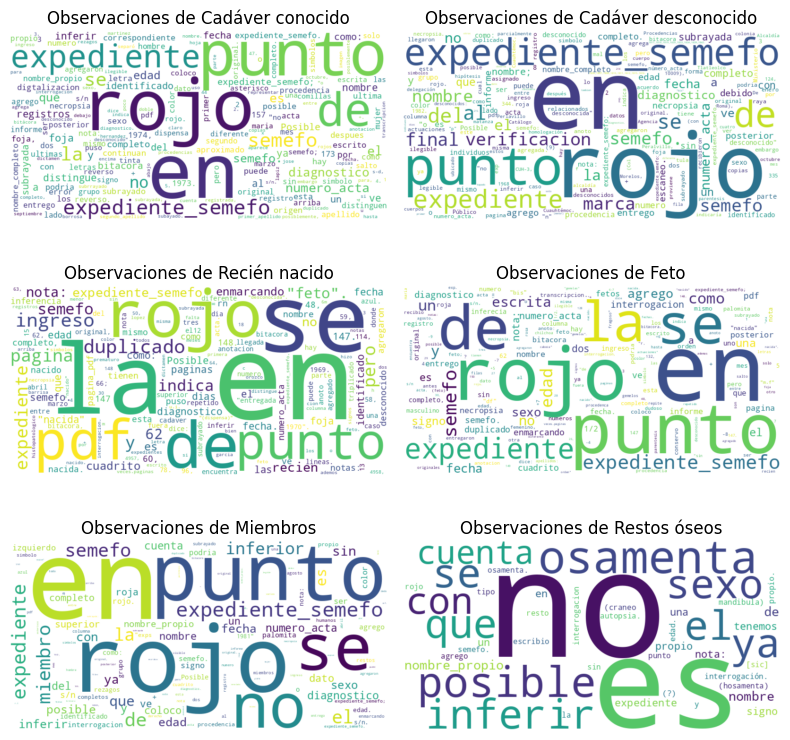

In [31]:
data = df.groupby('Tipo_restos').agg({'Observaciones':join_strings_with_nans})
data = data.to_dict()['Observaciones']
data

fig, axes = plt.subplots(nrows=3, ncols=2,figsize=(8,8))
axes = axes.flatten()

for ax,text in zip(axes,data.items()):
    # get word frequency
    freq = {}
    for word in text[1].split():
        freq[word] = freq.get(word, 0) + 1
    # create wordcloudx
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          background_color='white') \
                          .generate_from_frequencies(freq)
    # Display the word cloud
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f"Observaciones de {text[0]}")

plt.tight_layout()
plt.show()

### Numéricas
#### Edad


In [32]:
numeric_summary(df['Edad_estandar'],df['Tipo_restos'],percen_round=3)

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,All
count,32348,6094,223,1174,329,3,40171
mean,35.845,40.057,0,0,35.587,26,35.235
std,22.084,17.54,0,0,19.799,12.49,22.127
min,0,0,0,0,0,16,0
25%,20,28,0,0,20,19,20
50%,33,40,0,0,30,22,34
75%,52,50,0,0,48,31,50
max,108,90,0,0,91,40,108


Crearemos un subconjunto de datos con edades redondeadas y agrupando los mayores de 100 años

In [33]:
data_edad = df[['Tipo_restos', 'Edad_estandar', 'Edad_grupo', 'Sexo', 'Fecha_año']].dropna()
data_edad['Edad_estandar'] = data_edad['Edad_estandar'].astype(int) \
        .replace({n:100 for n in range(100,110)})
data_edad['Fecha_año'] = data_edad['Fecha_año'].astype(int)
data_edad

,Tipo_restos,Edad_estandar,Edad_grupo,Sexo,Fecha_año
ID,,,,,
BO_1971_01274,Cadáver conocido,0,"[0, 1)",Masculino,1971
BO_1973_00107,Recién nacido,0,"[0, 1)",Masculino,1973
BO_1973_01155,Cadáver desconocido,0,"[0, 1)",Femenino,1973
BO_1973_02920,Cadáver desconocido,0,"[0, 1)",Masculino,1973
BO_1973_03132,Cadáver desconocido,0,"[0, 1)",Masculino,1973
...,...,...,...,...,...
BO_1979_07440,Miembros,23,"[20, 25)",Masculino,1979
BO_1979_07442,Miembros,17,"[15, 20)",Masculino,1979
BO_1979_07451,Miembros,22,"[20, 25)",Masculino,1979


Ingresos por grupo de edad

In [66]:
round(data_edad['Edad_grupo'].value_counts(normalize=True).head(10),4)*100

Edad_grupo
[25, 30)    9.52
[20, 25)    9.49
[35, 40)    8.01
[30, 35)    7.54
[40, 45)    6.85
[45, 50)    6.66
[0, 1)      6.47
[15, 20)    6.10
[50, 55)    5.87
[1, 5)      4.87
Name: proportion, dtype: float64

Graficamos la frecuencia de edad

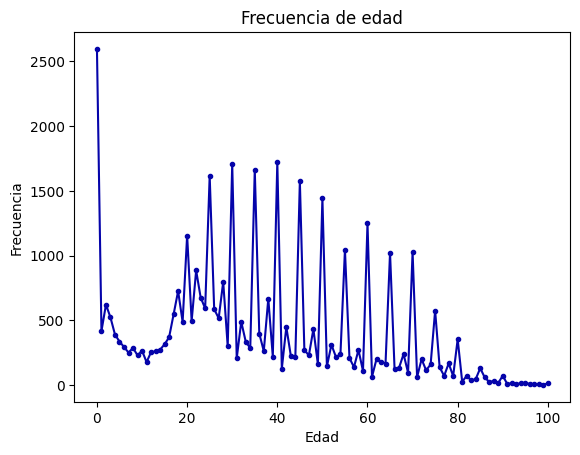

In [34]:
data_total = data_edad.value_counts('Edad_estandar').sort_index()
data_total.plot(style='.-', title="Frecuencia de edad",
               xlabel='Edad', ylabel='Frecuencia', color=dic_color['Poblacion'],
              )
plt.show()

#### Distribución esperada (KDE)

Están fuertemente sobrerrepresentadas las edades de múltiplo de 5 en los datos.

Calculemos la densidad de la probabilidad de la población con un KDE Gaussiano.

> Un Estimador de Densidad de Kernel (KDE) es una técnica para estimar la función de densidad de probabilidad de una variable aleatoria a partir de datos.  Es un método no paramétrico, lo que significa que no asume una forma específica para la distribución. El KDE funciona colocando una pequeña curva suave (llamada kernel, como una campana) sobre cada punto de datos. Luego, suma y promedia estas curvas para crear una única curva continua que representa la distribución. La suavidad de esta curva final se controla por un parámetro llamado ancho de banda.

40125

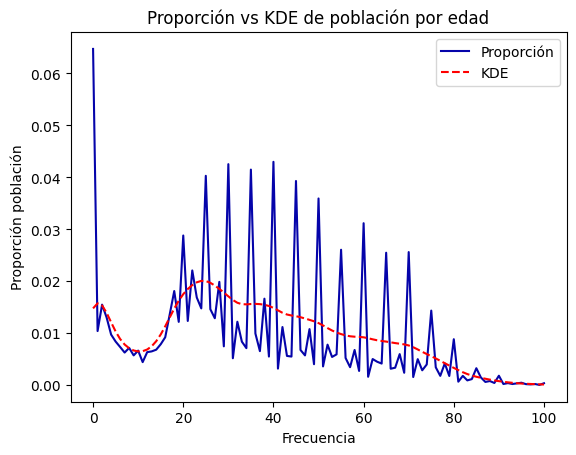

In [36]:
# Your frequency data
data_total = data_edad.value_counts('Edad_estandar').sort_index()
freq = data_total.values
values = data_total.index

# Create a "raw" data array
raw_data = np.repeat(values, freq)
total_observations = len(raw_data)
display(total_observations)

# Estimate KDE from the raw data
kde = gaussian_kde(raw_data)
kde_density = kde(values)

# Plot
plt.plot(values, freq/total_observations, label='Proporción', color=dic_color['Poblacion'])
plt.plot(values, kde_density, color='red', linestyle='--', label='KDE')
plt.title('Proporción vs KDE de población por edad')
plt.xlabel('Frecuencia')
plt.ylabel('Proporción población')
plt.legend()
#plt.savefig("imagenes/Edad+FreqKDE.svg")
plt.show()

Ahora, veamos la distancia entre la frecuencia reportada por edad y la estimada con el KDE.

La estimación de KDE es buena, ya que en promedio hay una distancia de 0.000349 entre frecuencia reportada y estimada.

In [37]:
data_kde = pd.DataFrame({'Edad':values, 
                         'Freq':freq,
                         'KDE_scaled':kde_density*total_observations,
                         'Prop':freq/total_observations, 
                         'KDE':kde_density})
data_kde = data_kde
data_kde['Diff'] = data_kde['Freq'] -  data_kde['KDE_scaled']
data_kde['Diff_norm'] = data_kde['Prop'] -  data_kde['KDE']
data_kde['Grupo'] = data_kde['Edad'].mod(5)
data_kde.loc[data_kde['Edad']<=18,'Grupo'] = 'Menor edad'
data_kde.loc[data_kde['Edad']==0,'Grupo'] = 'Cero años'
data_kde['Grupo'] = data_kde['Grupo'].replace({0:'Múltiplo 5', 1:'Otros múltiplos', 
                                               2:'Otros múltiplos', 3:'Otros múltiplos', 4:'Otros múltiplos'})
display( data_kde.drop(columns='Grupo').mean() )

Edad           50.000000
Freq          397.277228
KDE_scaled    383.276718
Prop            0.009901
KDE             0.009552
Diff           14.000509
Diff_norm       0.000349
dtype: float64

La diferencia por grupo es muy diferente:
* 0 años: error por múltiples factores, ignorar
* Menores de edad, subestimación de -776.38 (-1.93%) registros
* Múltiplo 5, sobreestimación de 10097.58 (25.16%) registros
* Otros múltiplos, subestimación de -9906.34 (-24.69%) registros
 
Dada la sobrerrepresentación de edades múltiplos de 5, podemos suponer que se estimó la edad de 1 de cada 4 ingresos.

Por lo tanto, mejor trabajar con grupos de edad.

In [38]:
data_kde.groupby('Grupo').agg(
            tamano_grupo = ('Freq', 'size'),
            tamano_reportado = ('Freq', 'sum'),
            tamano_esperado = ('KDE_scaled', 'sum'),
            diff_sum_grupo = ('Diff', 'sum'),
            diff_norm_sum_grupo = ('Diff_norm', 'sum'),
)

,tamano_grupo,tamano_reportado,tamano_esperado,diff_sum_grupo,diff_norm_sum_grupo
Grupo,,,,,
Cero años,1,2597,593.211222,2003.788778,0.049939
Menor edad,18,6551,7331.952578,-780.952578,-0.019463
Múltiplo 5,17,16406,6308.432569,10097.567431,0.251653
Otros múltiplos,65,14571,24477.352184,-9906.352184,-0.246887


#### Edad vs Tipo restos (chi^2)


**Prueba de independencia $\chi^2$**

Supuestos:
* Variables Categóricas
* Observaciones Independientes: 
* Frecuencias Esperadas Suficientes: usar cadaver des/conocido y miembros
* Muestra Aleatoria Simple

Resultado:
**Muestra no independientes**: Chi-square: 1597.88
**Estadísticamente significativa**: P-value: 0.0

In [61]:
#display(categorical_summary(data_edad['Edad_grupo'], data_edad['Tipo_restos'], percen_round=3, as_str=True))

data = data_edad.pivot_table(index='Edad_grupo',columns='Tipo_restos', aggfunc='size')
data = data[['Cadáver conocido','Cadáver desconocido', 'Miembros']]
#display(data)
display( round(data / data.sum(),4)*100 )

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid = resid.where(np.abs(resid) > thr_resid)
#display( resid )

Tipo_restos,Cadáver conocido,Cadáver desconocido,Miembros
Edad_grupo,,,
"[0, 1)",2.99,3.81,0.91
"[1, 5)",5.87,0.87,1.52
"[5, 10)",4.18,0.72,2.74
"[10, 15)",3.63,0.76,4.56
"[15, 20)",7.05,2.17,11.85
"[20, 25)",10.47,6.16,14.59
"[25, 30)",9.64,10.92,12.46
"[30, 35)",7.51,9.46,7.29
"[35, 40)",7.67,11.76,6.38


Chi-square statistic: 1597.8831649056688
Degrees of freedom: 36
P-value: 0.0


#### Edad vs Sexo (chi^2)

**Prueba de independencia $\chi^2$**

Supuestos:
* Variables Categóricas
* Observaciones Independientes:
* Frecuencias Esperadas Suficientes: quitar `Restos óseos`
* Muestra Aleatoria Simple

Resultado:
**Muestra no independientes**: Chi-square: 2254.63
**Estadísticamente significativa**: P-value: 0.0

In [40]:
#display(categorical_summary(data_edad['Edad_grupo'], data_edad['Sexo'], percen_round=3, as_str=True))

data = data_edad.pivot_table(index='Edad_grupo',columns='Sexo', aggfunc='size')
data = data.drop(columns='S-D')

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid = resid.where(np.abs(resid) > thr_resid)
#display( resid )

Chi-square statistic: 2254.63093761038
Degrees of freedom: 18
P-value: 0.0


#### Edad vs Sexo (Mann-Whitney U)

**Diferente distribución Mann-Whitney U**

Supuestos:
* Variables ordinales o continuas
* Observaciones independientes

Resultado:
**Distribuciones diferentes**: U: 150473844
**Estadísticamente significativa**: P-value: 0.0

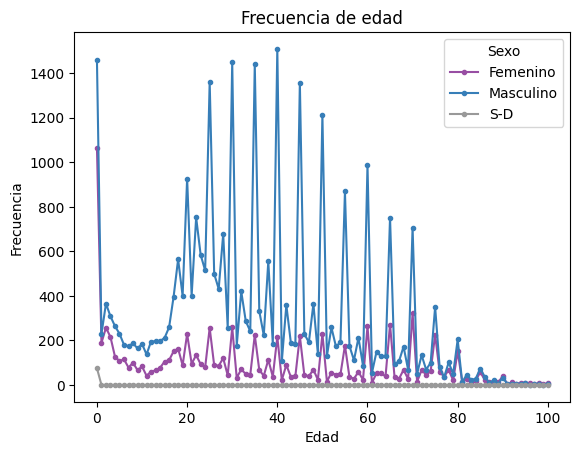

Estadístico U: 150474828.5000
Valor p: 0.0000


In [41]:
data_sexo = data_edad.pivot_table(index='Edad_estandar', columns='Sexo', aggfunc='size')
data_sexo.plot(style='.-', title="Frecuencia de edad",
               xlabel='Edad', ylabel='Frecuencia', color=dic_color,
              )
plt.show()

edad_masculino = data_edad.loc[data_edad['Sexo']=='Masculino', 'Edad_estandar'].dropna().values
edad_femenino = data_edad.loc[data_edad['Sexo']=='Femenino', 'Edad_estandar'].dropna().values
u_statistic, p_value = mannwhitneyu(edad_masculino, edad_femenino, alternative='two-sided')
print(f"Estadístico U: {u_statistic:.4f}")
print(f"Valor p: {p_value:.4f}")

## Comparación con datos históricos

Cargando archivos de referencia del INEGI

Datos tomados de:
* Secretaría de Programación y Presupuesto. (1982). Defunciones registradas en la República Mexicana, 1933-1975. Coordinación General de los Servicios Nacionales de Estadística, Geografía e Informática. ISBN 968-809-593-1.
* Instituto Nacional de Estadística, Geografía e Informática. (1994). Defunciones en los Estados Unidos Mexicanos, 1976-1992. INEGI. ISBN 970-13-0098-X.

In [42]:
años_edad = [1974,1975,1976,1977,1978,1979]
grupos_edad = ['[0, 1)', '[1, 5)', '[5, 10)', '[10, 15)', '[15, 20)', '[20, 25)', '[25, 30)', 
              '[30, 35)', '[35, 40)', '[40, 45)', '[45, 50)', '[50, 55)', '[55, 60)', 
              '[60, 65)', '[65, 70)', '[70, 75)', '[75, 80)', '[80, 85)', '[85, 110)']

df_inegi = pd.read_csv('data_raw/INEGI_defunciones_sexo_1966-1984.csv', index_col='Edad_grupo')
df_inegi.columns = [int(i) if i.startswith('19') else i for i in df_inegi.columns]
df_inegi

,Sexo,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984
Edad_grupo,,,,,,,,,,,,,,,,,,,,
Total,Total,53820.0,56693.0,59872.0,62937.0,66158.0,64301.0,66804.0,55052.0,52767.0,50631.0,51284,47637,47741,48421,49848,48486,47715,48947,46777
Masculino,Masculino,28365.0,29981.0,31704.0,33265.0,35088.0,34279.0,35583.0,29211.0,28045.0,26854.0,27102,25289,25267,26073,26876,26210,25851,26505,24762
"[0, 1)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13268.0,12886.0,12153,10954,8402,9862,9857,8972,8614,8370,7423
"[1, 2)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,527.0,533.0,616,411,358,368,282,290,289,268,241
"[2, 3)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,203.0,206.0,257,182,178,170,144,115,103,117,92
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"[70, 75)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,5,2,1,4,5,4,3
"[75, 80)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1,2,0,5,4,2,4
"[80, 85)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1,1,1,2,5,5,4


### Asociación de ingresos y decesos DF (chi^2 y regresión lineal)

,Decesos DF,Ingresos SEMEFO
1968,59872,4655.0
1969,62937,4962.0
1970,66158,5193.0
1971,64301,5415.0
1972,66804,5632.0
1973,55052,6085.0
1974,52767,5810.0
1975,50631,6684.0
1976,51284,6749.0
1977,47637,6938.0


<Axes: title={'center': 'Defunciones vs ingresos al SEMEFO-DF'}>

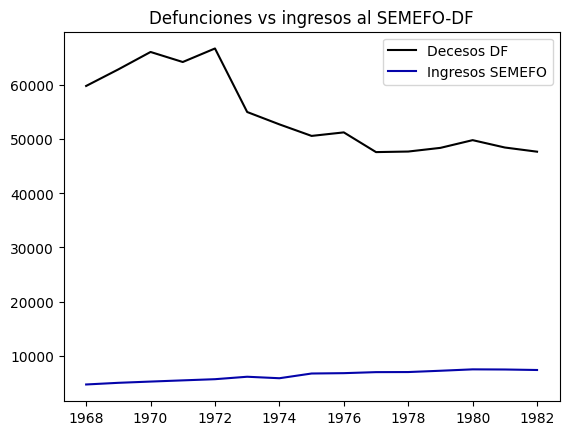

In [43]:
# Decesos/ingresos por dataset
data_inegi = df_inegi.loc['Total'].drop('Sexo').apply(int)
tipos_no = ['Miembros', 'Restos óseos']
data_semefo = df.loc[~df['Tipo_restos'].isin(tipos_no), 'Fecha_año'].value_counts()
# Graficar
data = pd.concat([data_inegi,data_semefo], axis=1).dropna()
data.columns = ['Decesos DF', 'Ingresos SEMEFO']
display(data)
data.plot(title="Defunciones vs ingresos al SEMEFO-DF", color=['black', dic_color['Poblacion']])

**Prueba de independencia $\chi^2$**

Supuestos:
* Observaciones Independientes:
* Frecuencias Esperadas Suficientes: quitar `Restos óseos`
* Muestra Aleatoria Simple

Resultado:
**Muestras no independientes**: Chi-square: 5878.77
**Estadísticamente significativa**: P-value: 0.0

In [44]:
# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid = resid.where(np.abs(resid) > thr_resid)
#display( resid )

Chi-square statistic: 5878.7700752143755
Degrees of freedom: 14
P-value: 0.0


**Regresión Lineal**  
Variable independiente: año (X)  
Variable dependiente: decesos/ingresos (Y)
$$Y=\beta_0+\beta_1 X+\epsilon$$

Supuestos
* Linealidad
* Independencia
* Homocedasticidad: La varianza de los residuos es constante
* Normalidad residuos

Resultado Decesos DF:
**R-squared**: 0.730
**Estadísticamente significativa**: F-statistic: 4.96e-05
**Pendiente $\beta_1$**: -1394.2036

Resultado Ingresos SEMEFO:
**R-squared**: 0.950
**Estadísticamente significativa**: F-statistic: 7.33e-10
**Pendiente $\beta_1$**: 209.1143

In [45]:
# Variable independiente (Año)
X = sm.add_constant([i for i in data.index])

# Regresión Decesos DF vs Año
y1 = data['Decesos DF']
model1 = sm.OLS(y1, X).fit()
print('Decesos DF vs. Año')
print(model1.summary())

# Regresión Decesos DF vs Año
y2 = data['Ingresos SEMEFO']
model1 = sm.OLS(y2, X).fit()
print('Ingresos SEMEFO vs. Año')
print(model1.summary())

Decesos DF vs. Año
                            OLS Regression Results                            
Dep. Variable:             Decesos DF   R-squared:                       0.730
Model:                            OLS   Adj. R-squared:                  0.710
Method:                 Least Squares   F-statistic:                     35.20
Date:                Wed, 24 Sep 2025   Prob (F-statistic):           4.96e-05
Time:                        15:01:08   Log-Likelihood:                -144.37
No. Observations:                  15   AIC:                             292.7
Df Residuals:                      13   BIC:                             294.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.808e+06   4.64e+05 

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:430: UserWarning:

`kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=15 observations were given.

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:430: UserWarning:

`kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=15 observations were given.



### Ingresos anuales por sexo

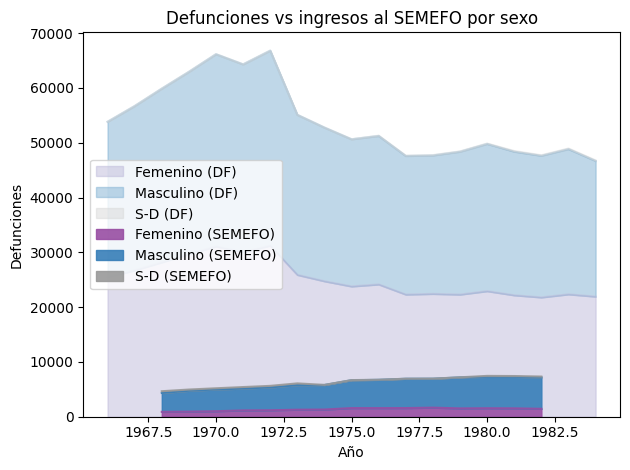

In [46]:
# Ingresos anuales semefo
data_semefo = df.loc[~df['Tipo_restos'].isin(tipos_no)] \
                .pivot_table(index='Fecha_año', columns='Sexo', aggfunc='size')
data_semefo.index = [int(i) for i in data_semefo.index]
data_semefo.columns = [f'{c} (SEMEFO)' for c in data_semefo.columns]

# Defunciones anuales DF
data_inegi = df_inegi.loc[['Femenino','Masculino','S-D']].transpose().drop('Sexo')
data_inegi.index = [i for i in data_inegi.index]
data_inegi.columns = [f'{c} (DF)' for c in data_inegi.columns]

# Plot
fig, ax = plt.subplots()
data_inegi.plot.area(ax=ax, alpha=0.5, color=dic_color)
data_semefo.plot.area(ax=ax, alpha=0.9, color=dic_color)
ax.set_xlabel('Año')
ax.set_ylabel('Defunciones')
ax.set_title('Defunciones vs ingresos al SEMEFO por sexo')
ax.legend(loc='center left')
plt.tight_layout()
#plt.savefig("imagenes/BO_Año+Sexo_DF+SEMEFO.svg")
plt.show()

### Distribución grupo etario

In [48]:
data_semefo = data_edad.loc[ (~data_edad['Tipo_restos'].isin(tipos_no)) 
                           & (data_edad['Sexo']!='S-D') \
                           & (data_edad['Fecha_año'].isin(años_edad))]
data_semefo['Sexo'] = data_semefo['Sexo'].astype(str)
data_semefo['Edad_grupo'] = data_semefo['Edad_grupo'].astype(str)
data_semefo = data_semefo.groupby(['Sexo','Edad_grupo']).size().rename('Freq').reset_index()
data_semefo['Origen'] = 'SEMEFO'

data_inegi = df_inegi.set_index(['Sexo'], append=True)[años_edad].sum(axis=1).astype(int).rename('Freq').reset_index()
data_inegi = data_inegi.loc[(data_inegi['Edad_grupo'].isin(grupos_edad)) & (data_inegi['Sexo'].isin(['Femenino','Masculino']))]
data_inegi['Origen'] = 'DF'

data_otro = pd.merge(data_inegi, data_semefo, on=['Sexo','Edad_grupo'])
data_otro['Freq'] = data_otro['Freq_x']-data_otro['Freq_y']
data_otro = data_otro[['Edad_grupo','Sexo','Freq']]
data_otro['Origen'] = 'otro'

data_tidy = pd.concat([data_semefo, data_otro, data_inegi])
data_tidy['Etiqueta'] = data_tidy['Sexo'] +' (' +data_tidy['Origen'] +')'
data_tidy['Sexo'] = data_tidy['Sexo'].astype('category')
data_tidy['Origen'] = data_tidy['Origen'].astype('category')
data_tidy['Edad_grupo'] = pd.Categorical(data_tidy['Edad_grupo'], categories=grupos_edad, ordered=True)
data_tidy = data_tidy.sort_values(['Origen','Sexo','Edad_grupo'])
data_tidy

,Sexo,Edad_grupo,Freq,Origen,Etiqueta
27,Femenino,"[0, 1)",52068,DF,Femenino (DF)
32,Femenino,"[1, 5)",4600,DF,Femenino (DF)
33,Femenino,"[5, 10)",1409,DF,Femenino (DF)
34,Femenino,"[10, 15)",1131,DF,Femenino (DF)
35,Femenino,"[15, 20)",1946,DF,Femenino (DF)
...,...,...,...,...,...
14,Masculino,"[65, 70)",9073,otro,Masculino (otro)
15,Masculino,"[70, 75)",9402,otro,Masculino (otro)
16,Masculino,"[75, 80)",8245,otro,Masculino (otro)
17,Masculino,"[80, 85)",4837,otro,Masculino (otro)


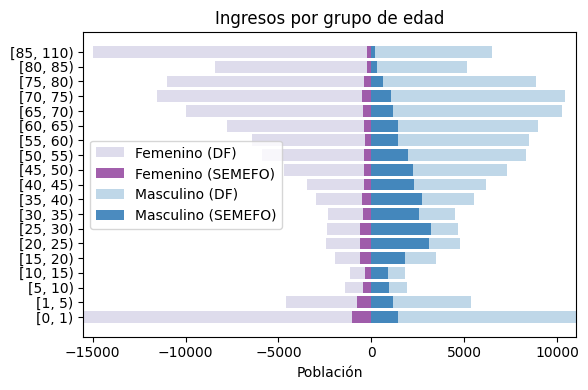

In [49]:
data = data_tidy.pivot(index='Edad_grupo', columns='Etiqueta', values='Freq')
data = data.drop(columns=(['Masculino (otro)','Femenino (otro)']))
#display( data.head() )

fig, ax = plt.subplots(figsize=(6, 4))
y = data.index
for col in data.columns:
    x = data[col]
    if 'Femenino' in col: x=-1*x
    if 'DF' in col: alpha=0.5
    else: alpha=0.9
    ax.barh(y,x,label=col,color=dic_color[col],alpha=alpha)
ax.set_xlabel('Población')
ax.set_title('Ingresos por grupo de edad')
ax.legend(loc='center left')
plt.xlim( -15500, 11000 )
plt.tight_layout()
#plt.savefig("imagenes/BO_PiramidePoblacional_DF+SEMEFO.svg")
plt.show()

Normalizando por el total de la población

In [50]:
data


Etiqueta,Femenino (DF),Femenino (SEMEFO),Masculino (DF),Masculino (SEMEFO)
Edad_grupo,,,,
"[0, 1)",52068,1060,67525,1449
"[1, 5)",4600,785,5366,1164
"[5, 10)",1409,464,1931,928
"[10, 15)",1131,320,1796,900
"[15, 20)",1946,606,3479,1802
"[20, 25)",2430,628,4778,3131
"[25, 30)",2367,589,4682,3189
"[30, 35)",2346,450,4486,2553
"[35, 40)",3005,477,5529,2716


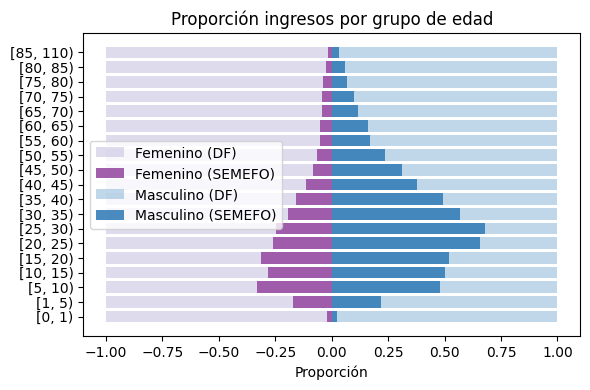

In [51]:
data_norm = pd.DataFrame()
data_norm['Femenino (DF)'] = data['Femenino (DF)']/data['Femenino (DF)']
data_norm['Femenino (SEMEFO)'] = data['Femenino (SEMEFO)']/data['Femenino (DF)']
data_norm['Masculino (DF)'] = data['Masculino (DF)']/data['Masculino (DF)']
data_norm['Masculino (SEMEFO)'] = data['Masculino (SEMEFO)']/data['Masculino (DF)']
#display(data_norm.head())

fig, ax = plt.subplots(figsize=(6, 4))
y = data_norm.index
for col in data_norm.columns:
    x = data_norm[col]
    if 'Femenino' in col: x=-1*x
    if 'DF' in col: alpha=0.5
    else: alpha=0.9
    ax.barh(y,x,label=col,color=dic_color[col],alpha=alpha)
ax.set_xlabel('Proporción')
ax.set_title('Proporción ingresos por grupo de edad')
ax.legend(loc='center left')
plt.tight_layout()
#plt.savefig("imagenes/BO_PiramidePoblacional_DF+SEMEFO.svg")
plt.show()